In [1]:
# ===================================================================================
#  CONFIG — Tuned Hyperparameters Annotated with Experimental Measurements
# ===================================================================================
class CFG:
    # --- Candidate Generation ------------------------------------------------------
    PPM_WIN      = 8.5    # Optimal window for timsTOF (+1.4 ppm systematic offset).
                          # Tighter is better: +-10 ppm -> 0.521, +-8.5 ppm -> 0.524 Class-2 MRR
    PPM_FALLBACK = 30.0   # Robust fallback if tight window yields 0 candidates

    # --- Spectral Preprocessing ----------------------------------------------------
    INT_FLOOR    = 0.002  # Drop peaks below 0.2% base-peak intensity
    MAX_PEAKS    = 256    # Keep N most intense peaks after floor
    MZ_TOL       = 0.01   # Da tolerance for peak alignment
    INT_POWER    = 1.0    # Linear intensity with entropy weighting outperforms sqrt
    ENT_WEIGHT   = True   # Entropy weighting for low-entropy spectra (Li et al. 2021)

    # --- Mass-Shifted Analog Propagation (Channel 2) --------------------------------
    ANALOG_WIN   = 200.0  # +- Da mass-shift search window
    N_ANALOG     = 100    # Analogs kept per molecule (scaled from 80 -> 100)
    SIM_POWER    = 4.0    # sim^p power weighting. p=1 -> 0.498, p=3 -> 0.521, p=4 -> 0.525

    # --- Calibrated Ensemble Ranker (Variance Reduction) ---------------------------
    W1_PRIORS    = (0.30, 0.60)  # Hedging Class-1/Class-2 trade-off improves LB by ~0.003
    SEEDS        = (0, 1, 2, 3)  # Bagging 4 random seeds eliminates 0.006 seed noise floor
    W1           = 0.50          # Calibrated class weight anchor
    GBM = dict(max_depth=10, max_iter=500, learning_rate=0.03,
               min_samples_leaf=80, l2_regularization=1.0)

    USE_BIO_DB   = False  # ChEBI/LIPID MAPS toggle (disabled by default to prevent decoy dilution)
    TOPN         = 25     # Output exactly 25 SMILES per molecule


In [2]:
import os, sys, glob, time, pickle, math, subprocess
from multiprocessing import Pool as MPool
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import pyarrow as pa
import matplotlib.pyplot as plt

T0 = time.time()

def find_file(name):
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    if not hits:
        raise FileNotFoundError(f"File not found in /kaggle/input: {name}")
    return sorted(hits, key=len)[0]

COMP   = os.path.dirname(find_file('test.parquet'))
TRAIN  = os.path.join(COMP, 'train.parquet')
TEST   = os.path.join(COMP, 'test.parquet')
SAMPLE = os.path.join(COMP, 'sample_submission.csv')

print(f"[INFO] Competition directory: {COMP}")
print(f"       Files available: {os.listdir(COMP)}")

# Bootstrap offline RDKit wheel if available in attached datasets
rdkit_whls = glob.glob('/kaggle/input/**/rdkit-*.whl', recursive=True)
if rdkit_whls:
    print(f"[INFO] Installing offline RDKit wheel: {rdkit_whls[0]}")
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-index', rdkit_whls[0]], check=False)

try:
    from rdkit import Chem, RDLogger
    from rdkit.Chem import rdFingerprintGenerator, MACCSkeys
    from rdkit.Chem.Descriptors import ExactMolWt
    RDLogger.DisableLog('rdApp.*')
    HAVE_RDKIT = True
    print("[SUCCESS] RDKit 2026.3.3 is active and verified.")
except Exception as e:
    HAVE_RDKIT = False
    print(f"[WARNING] RDKit unavailable ({e}). Running without in-silico fragmentation.")


[INFO] Competition directory: /kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra
       Files available: ['sample_submission.csv', 'train.parquet', 'test.parquet']
[INFO] Installing offline RDKit wheel: /kaggle/input/datasets/aidensong123/casmi26-offline-rdkit-2026033/rdkit-2026.3.3-cp312-cp312-manylinux_2_28_x86_64.whl
[SUCCESS] RDKit 2026.3.3 is active and verified.


In [3]:
import numpy as np
from numba import njit, prange

@njit(cache=True, fastmath=True)
def _clean(mz, it, floor, topk, power, ent_weight):
    n = len(mz)
    if n == 0:
        return np.empty(0, np.float32), np.empty(0, np.float32)
    mx = 0.0
    for i in range(n):
        if it[i] > mx: mx = it[i]
    if mx <= 0:
        return np.empty(0, np.float32), np.empty(0, np.float32)
    thr = floor * mx
    c = 0
    for i in range(n):
        if it[i] >= thr: c += 1
    idx = np.empty(c, np.int64)
    j = 0
    for i in range(n):
        if it[i] >= thr:
            idx[j] = i; j += 1
    if c > topk:
        v = np.empty(c, np.float32)
        for i in range(c): v[i] = it[idx[i]]
        o = np.argsort(v)[c - topk:]
        k2 = np.empty(topk, np.int64)
        for i in range(topk): k2[i] = idx[o[i]]
        k2.sort()
        idx = k2
        c = topk
    om = np.empty(c, np.float32)
    oi = np.empty(c, np.float32)
    s = 0.0
    for i in range(c):
        om[i] = mz[idx[i]]
        v = it[idx[i]] ** power
        oi[i] = v
        s += v
    if s > 0:
        for i in range(c): oi[i] /= s
    if ent_weight:
        S = 0.0
        for i in range(c):
            if oi[i] > 0: S -= oi[i] * np.log(oi[i])
        if S < 3.0:
            w = 0.25 + 0.25 * S
            s2 = 0.0
            for i in range(c):
                oi[i] = oi[i] ** w
                s2 += oi[i]
            if s2 > 0:
                for i in range(c): oi[i] /= s2
    return om, oi

@njit(cache=True, fastmath=True)
def entropy_sim(qmz, qp, cmz, cp, tol):
    i = 0; j = 0; n = len(qmz); m = len(cmz)
    SA = 0.0
    for x in range(n):
        if qp[x] > 0: SA -= qp[x] * np.log(qp[x])
    SB = 0.0
    for x in range(m):
        if cp[x] > 0: SB -= cp[x] * np.log(cp[x])
    SAB = 0.0; tot = 0.0
    buf = np.empty(n + m, np.float64); b = 0
    while i < n and j < m:
        d = qmz[i] - cmz[j]
        if d < -tol:
            buf[b] = qp[i]; i += 1; b += 1
        elif d > tol:
            buf[b] = cp[j]; j += 1; b += 1
        else:
            buf[b] = qp[i] + cp[j]; i += 1; j += 1; b += 1
    while i < n: buf[b] = qp[i]; i += 1; b += 1
    while j < m: buf[b] = cp[j]; j += 1; b += 1
    for x in range(b): tot += buf[x]
    if tot <= 0: return 0.0
    for x in range(b):
        v = buf[x] / tot
        if v > 0: SAB -= v * np.log(v)
    return 1.0 - (2.0 * SAB - SA - SB) / np.log(4.0)

@njit(cache=True, fastmath=True)
def entropy_sim_shift(qmz, qp, cmz, cp, tol, shift):
    """Evaluates max of direct and mass-shifted spectral entropy similarity."""
    a = entropy_sim(qmz, qp, cmz, cp, tol)
    if shift > -0.001 and shift < 0.001:
        return a
    sm = np.empty(len(cmz), np.float32)
    for i in range(len(cmz)):
        sm[i] = cmz[i] + shift
    b = entropy_sim(qmz, qp, sm, cp, tol)
    return a if a > b else b

@njit(cache=True, fastmath=True, parallel=True)
def search(qmz, qp, cand, off, allmz, allin, tol, floor, topk, power, ent_weight):
    out = np.zeros(len(cand), np.float32)
    for k in prange(len(cand)):
        c = cand[k]; a = off[c]; b = off[c + 1]
        if b <= a: continue
        cm, cp = _clean(allmz[a:b], allin[a:b], floor, topk, power, ent_weight)
        if len(cm) == 0: continue
        out[k] = entropy_sim(qmz, qp, cm, cp, tol)
    return out

@njit(cache=True, fastmath=True, parallel=True)
def search_shift(qmz, qp, cand, off, allmz, allin, tol, floor, topk, power, ent_weight, shift):
    out = np.zeros(len(cand), np.float32)
    for k in prange(len(cand)):
        c = cand[k]; a = off[c]; b = off[c + 1]
        if b <= a: continue
        cm, cp = _clean(allmz[a:b], allin[a:b], floor, topk, power, ent_weight)
        if len(cm) == 0: continue
        out[k] = entropy_sim_shift(qmz, qp, cm, cp, tol, shift[k])
    return out


In [4]:
# ===================================================================================
#  High-Precision Adduct Physics & Reference Library Construction
# ===================================================================================
MASS = dict(C=12.0, H=1.00782503207, N=14.0030740048, O=15.9949146196, P=30.97376163,
            S=31.97207100, F=18.99840322, Cl=34.96885268, Br=78.9183371, I=126.904473,
            Na=22.9897692809, K=38.96370668, Si=27.9769265325, B=11.0093054, Se=79.9165213)
E = 0.00054857990
PROTON = MASS['H'] - E
H2O = 2 * MASS['H'] + MASS['O']
NH4 = MASS['N'] + 4 * MASS['H']
FORMATE = MASS['C'] + 2 * MASS['H'] + 2 * MASS['O']
ACETATE = 2 * MASS['C'] + 4 * MASS['H'] + 2 * MASS['O']

ADDUCTS = {
    "[M+H]+": (1, 1, PROTON), "[M+NH4]+": (1, 1, NH4 - E), "[M+Na]+": (1, 1, MASS['Na'] - E),
    "[M+K]+": (1, 1, MASS['K'] - E), "[M-H2O+H]+": (1, 1, PROTON - H2O), "[M-2H2O+H]+": (1, 1, PROTON - 2*H2O),
    "[M+2H]2+": (1, 2, 2 * PROTON), "[M]+": (1, 1, -E), "[M-H2O]+": (1, 1, -E - H2O),
    "[M+CH3OH+H]+": (1, 1, PROTON + MASS['C'] + 4 * MASS['H'] + MASS['O']),
    "[M+CH3CN+H]+": (1, 1, PROTON + 2 * MASS['C'] + 3 * MASS['H'] + MASS['N']),
    "[M-H]-": (1, 1, -PROTON), "[M-H2O-H]-": (1, 1, -PROTON - H2O), "[M+CH2O2-H]-": (1, 1, FORMATE - PROTON),
    "[M+C2H4O2-H]-": (1, 1, ACETATE - PROTON), "[M+Cl]-": (1, 1, MASS['Cl'] + E), "[M]-": (1, 1, E),
    "[M-2H]-": (1, 2, -2 * PROTON), "[M+Na-2H]-": (1, 1, MASS['Na'] - 2 * PROTON),
    "[2M+H]+": (2, 1, PROTON), "[2M+Na]+": (2, 1, MASS['Na'] - E), "[2M+NH4]+": (2, 1, NH4 - E),
    "[2M+K]+": (2, 1, MASS['K'] - E), "[2M-H]-": (2, 1, -PROTON), "[2M+CH2O2-H]-": (2, 1, FORMATE - PROTON),
    "[2M+C2H4O2-H]-": (2, 1, ACETATE - PROTON), "[2M+Na-2H]-": (2, 1, MASS['Na'] - 2 * PROTON),
    "[3M+H]+": (3, 1, PROTON), "[3M-H]-": (3, 1, -PROTON),
}

def neutral_mass(mz, adduct):
    out = np.full(len(mz), np.nan)
    ad = np.asarray(adduct, dtype=object)
    for a, (n, z, d) in ADDUCTS.items():
        m = (ad == a)
        if m.any():
            out[m] = (mz[m] * z - d) / n
    return out

def load_library(path):
    t0 = time.time()
    t = pq.read_table(path, columns=['inchikey14', 'normalized_smiles', 'adduct', 'precursor_mz',
                                     'ms2_mzs', 'ms2_normalized_intensities'])
    mzc = t.column('ms2_mzs').combine_chunks()
    itc = t.column('ms2_normalized_intensities').combine_chunks()
    off = mzc.offsets.to_numpy().astype(np.int64)
    allmz = mzc.values.to_numpy(zero_copy_only=False).astype(np.float32)
    allin = itc.values.to_numpy(zero_copy_only=False).astype(np.float32)
    prec = t.column('precursor_mz').to_numpy(zero_copy_only=False).astype(np.float64)
    add = np.asarray(t.column('adduct').cast(pa.string()).to_pylist(), dtype=object)
    ik  = np.asarray(t.column('inchikey14').cast(pa.string()).to_pylist(), dtype=object)
    smi = np.asarray(t.column('normalized_smiles').cast(pa.string()).to_pylist(), dtype=object)
    nm  = neutral_mass(prec, add)
    ok  = np.isfinite(nm)
    order = np.argsort(np.where(ok, nm, 1e18), kind='mergesort')
    best = {}
    for k, s in zip(ik, smi):
        if k and s and k not in best:
            best[k] = s
    print(f"[INFO] Reference Library loaded: {len(off)-1:,} spectra / {len(best):,} unique structures ({time.time()-t0:.1f}s)", flush=True)
    return dict(off=off, mz=allmz, it=allin, nm=nm, ik=ik, best=best,
                order=order, snm=nm[order], n_ok=int(ok.sum()))

def lib_window(L, target, tol):
    lo = np.searchsorted(L['snm'][:L['n_ok']], target - tol, 'left')
    hi = np.searchsorted(L['snm'][:L['n_ok']], target + tol, 'right')
    return L['order'][lo:hi]

def build_rep(L):
    """Extracts the single richest representative spectrum per unique structure for analog retrieval."""
    npk = np.diff(L['off'])
    best = {}; ik = L['ik']
    for i in range(len(ik)):
        k = ik[i]
        if k and (k not in best or npk[i] > npk[best[k]]):
            best[k] = i
    rep = np.array(sorted(best.values()))
    nm = L['nm'][rep]
    ok = np.isfinite(nm)
    rep = rep[ok]; nm = nm[ok]; key = ik[rep]
    o = np.argsort(nm)
    print(f"[INFO] Built representative analog set: {len(rep):,} unique scaffolds.", flush=True)
    return rep[o], key[o], nm[o]


In [5]:
# ===================================================================================
#  Unified Candidate Pool: Loaded in 5s from Precomputed Artifacts
# ===================================================================================
t_pool = time.time()
pool_file = find_file('pool_712k_precomputed.npz')
pool_npz = np.load(pool_file, allow_pickle=True)

class CandidatePool:
    def __init__(self, npz):
        self.fp = npz['fp']
        self.mass = npz['mass']
        self.keys = npz['keys']
        self.smiles = npz['smiles']
        self.nbits = int(npz['nbits'])
        self.k2i = {k: i for i, k in enumerate(self.keys)}
    def window(self, target, ppm):
        tol = target * ppm / 1e6
        lo = int(np.searchsorted(self.mass, target - tol, side='left'))
        hi = int(np.searchsorted(self.mass, target + tol, side='right'))
        return np.arange(lo, hi)
    def fps(self, indices):
        return np.unpackbits(self.fp[indices], axis=1)[:, :self.nbits]

pool = CandidatePool(pool_npz)
print(f"[SUCCESS] 712k Candidate Pool ({len(pool.mass):,} structures) loaded in {time.time()-t_pool:.2f}s")


[SUCCESS] 712k Candidate Pool (712,199 structures) loaded in 4.75s


In [6]:
# ===================================================================================
#  Evidence Channels: Direct Library Match, Analog Match & MetFrag-lite
# ===================================================================================
AMU = {'C':12.0, 'H':1.00782503207, 'N':14.0030740048, 'O':15.9949146196, 'P':30.97376163,
       'S':31.97207100, 'F':18.99840322, 'Cl':34.96885268, 'Br':78.9183371, 'I':126.904473,
       'Na':22.9897692809, 'K':38.96370668, 'Si':27.9769265325, 'B':11.0093054, 'Se':79.9165213}
H_ATOM = AMU['H']
PROTON_MASS = H_ATOM - 0.00054857990

def clean_spectrum(mz, it):
    return _clean(np.asarray(mz, np.float32), np.asarray(it, np.float32),
                  CFG.INT_FLOOR, CFG.MAX_PEAKS, CFG.INT_POWER, CFG.ENT_WEIGHT)

def lib_sim(L, specs, target):
    """CLASS 1: Direct match against library spectra within tight neutral mass window."""
    cand = lib_window(L, target, target * CFG.PPM_WIN / 1e6)
    if len(cand) == 0: return {}
    agg = {}
    for mz, it in specs:
        qm, qp = clean_spectrum(mz, it)
        if len(qm) == 0: continue
        sc = search(qm, qp, cand, L['off'], L['mz'], L['it'],
                    CFG.MZ_TOL, CFG.INT_FLOOR, CFG.MAX_PEAKS, CFG.INT_POWER, CFG.ENT_WEIGHT)
        for c, s in zip(cand, sc):
            k = L['ik'][c]
            if s > agg.get(k, -1.0):
                agg[k] = float(s)
    return agg

def analog_sim(L, specs, target, rep, rep_key, rep_nm):
    """CLASS 2: Mass-shifted spectral entropy match across wide +-200 Da window."""
    lo = np.searchsorted(rep_nm, target - CFG.ANALOG_WIN, 'left')
    hi = np.searchsorted(rep_nm, target + CFG.ANALOG_WIN, 'right')
    cand = rep[lo:hi]
    if len(cand) == 0: return []
    shift = (target - rep_nm[lo:hi]).astype(np.float32)
    ckey = rep_key[lo:hi]
    agg = {}
    for mz, it in specs:
        qm, qp = clean_spectrum(mz, it)
        if len(qm) == 0: continue
        sc = search_shift(qm, qp, cand, L['off'], L['mz'], L['it'],
                          CFG.MZ_TOL, CFG.INT_FLOOR, CFG.MAX_PEAKS,
                          CFG.INT_POWER, CFG.ENT_WEIGHT, shift)
        for c, k, s in zip(cand, ckey, sc):
            if s > agg.get(k, -1.0):
                agg[k] = float(s)
    return sorted(agg.items(), key=lambda x: -x[1])[:CFG.N_ANALOG]

# MetFrag-lite: In-silico 1-2 bond fragmentation
def mol_graph(smi):
    if not HAVE_RDKIT: return None
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    n = m.GetNumAtoms()
    w = np.zeros(n)
    for a in m.GetAtoms():
        w[a.GetIdx()] = AMU.get(a.GetSymbol(), 0.0) + a.GetTotalNumHs() * H_ATOM
    if (w == 0).any(): return None
    bonds = [(b.GetBeginAtomIdx(), b.GetEndAtomIdx()) for b in m.GetBonds()]
    return w, bonds, n

def _components(n, bonds, drop):
    adj = [[] for _ in range(n)]
    for i, (a, b) in enumerate(bonds):
        if i in drop: continue
        adj[a].append(b); adj[b].append(a)
    seen = np.zeros(n, bool); comps = []
    for s in range(n):
        if seen[s]: continue
        stack = [s]; seen[s] = True; cur = [s]
        while stack:
            u = stack.pop()
            for v in adj[u]:
                if not seen[v]: seen[v] = True; stack.append(v); cur.append(v)
        comps.append(cur)
    return comps

def fragment_masses(smi, max_breaks=2, max_bonds=34):
    g = mol_graph(smi)
    if g is None: return np.zeros(0)
    w, bonds, n = g
    nb = len(bonds)
    if nb == 0 or nb > max_bonds: return np.array([w.sum()])
    out = {w.sum()}
    for i in range(nb):
        for c in _components(n, bonds, {i}):
            out.add(float(w[c].sum()))
    if max_breaks >= 2:
        for i in range(nb):
            for j in range(i + 1, nb):
                for c in _components(n, bonds, {i, j}):
                    out.add(float(w[c].sum()))
    return np.array(sorted(out))

def explain_score(frag_mass, peak_mz, peak_int, mode=1.0, tol=0.01, h_shifts=(-2, -1, 0, 1, 2)):
    if len(frag_mass) == 0 or len(peak_mz) == 0: return 0.0
    ion = []
    for dh in h_shifts:
        ion.append(frag_mass + dh * H_ATOM + (PROTON_MASS if mode > 0 else -PROTON_MASS))
    ion = np.sort(np.concatenate(ion))
    w = np.sqrt(np.asarray(peak_int, float)); tot = w.sum()
    if tot <= 0: return 0.0
    idx = np.searchsorted(ion, peak_mz)
    ok = np.zeros(len(peak_mz), bool)
    for off in (-1, 0):
        k = np.clip(idx + off, 0, len(ion) - 1)
        ok |= np.abs(ion[k] - peak_mz) <= tol
    return float(w[ok].sum() / tot)

def _frag_masses_wrapper(smi):
    try: return fragment_masses(smi)
    except Exception: return np.zeros(0)

def frag_scores(cand_smiles, specs, mode, workers=4):
    if not HAVE_RDKIT:
        return np.zeros(len(cand_smiles), np.float32)
    with MPool(workers) as mp:
        frags = mp.map(_frag_masses_wrapper, cand_smiles, chunksize=8)
    peaks = []
    for mz, it in specs:
        m2, i2 = _clean(np.asarray(mz, np.float32), np.asarray(it, np.float32),
                        CFG.INT_FLOOR, CFG.MAX_PEAKS, 1.0, False)
        peaks.append((np.asarray(m2, float), np.asarray(i2, float)))
    out = np.zeros(len(cand_smiles), np.float32)
    for j, f in enumerate(frags):
        out[j] = max((explain_score(f, a, b, mode=mode, tol=CFG.MZ_TOL) for a, b in peaks), default=0.0)
    return out


In [7]:
# ===================================================================================
#  Channel 4: Neural Spectrum -> Molecular Fingerprint Model (FPNet)
#  Ranking is f . z (Exact Bayes log-likelihood dot product)
# ===================================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
MAX_PEAKS_NN = 128
ADDUCT_LIST = ["[M+H]+","[M+NH4]+","[M+Na]+","[M+K]+","[M-H2O+H]+","[M-2H2O+H]+","[M]+",
               "[M-H]-","[M-H2O-H]-","[M+CH2O2-H]-","[M+C2H4O2-H]-","[M+Cl]-","[M]-",
               "[M+2H]2+","[M-2H]-","[2M+H]+","[2M+Na]+","[2M+NH4]+","[2M-H]-","[2M+K]+",
               "[2M+CH2O2-H]-","[2M+C2H4O2-H]-","[2M+Na-2H]-","[M+Na-2H]-","[M-H2O]+","<unk>"]
ADDUCT_IX = {a: i for i, a in enumerate(ADDUCT_LIST)}
INSTR_LIST = ["timsTOF", "Orbitrap", "QTOF", "IT", "other"]
INSTR_IX = {a: i for i, a in enumerate(INSTR_LIST)}
def instr_family(s):
    if s is None: return 4
    t = str(s).lower()
    if 'timstof' in t: return 0
    if 'orbitrap' in t or 'qft' in t or 'ftms' in t or 'hybrid ft' in t or 'itft' in t or 'exactive' in t: return 1
    if 'tof' in t: return 2
    if 'trap' in t or 'qq' in t: return 3
    return 4
def prep_peaks(mz, inten, prec_mz, max_peaks=MAX_PEAKS_NN, floor=1e-3, win=50.0, per_win=8):
    mz = np.asarray(mz, np.float64); it = np.asarray(inten, np.float64)
    if len(mz) == 0: return np.zeros(0, np.float32), np.zeros(0, np.float32)
    keep = (mz <= prec_mz + 1.5)
    mz, it = mz[keep], it[keep]
    if len(mz) == 0: return np.zeros(0, np.float32), np.zeros(0, np.float32)
    mx = it.max()
    if mx <= 0: return np.zeros(0, np.float32), np.zeros(0, np.float32)
    keep = it >= floor * mx
    mz, it = mz[keep], it[keep]
    if len(mz) > max_peaks:
        order = np.argsort(-it)
        bucket = (mz // win).astype(np.int64)
        cnt = {}; sel = []
        for i in order:
            b = bucket[i]; c = cnt.get(b, 0)
            if c < per_win: cnt[b] = c + 1; sel.append(i)
        sel = np.array(sel)
        if len(sel) > max_peaks:
            sel = sel[np.argsort(-it[sel])[:max_peaks]]
        elif len(sel) < max_peaks:
            rest = np.array([i for i in order if i not in set(sel.tolist())])
            need = max_peaks - len(sel)
            if len(rest): sel = np.concatenate([sel, rest[:need]])
        mz, it = mz[sel], it[sel]
    o = np.argsort(mz)
    mz, it = mz[o], it[o]
    v = np.sqrt(it / it.max())
    return mz.astype(np.float32), v.astype(np.float32)
class SinEmb(nn.Module):
    def __init__(self, dim, lo=-2.0, hi=3.2, power=1.0):
        super().__init__()
        n = dim // 2
        wav = torch.pow(10.0, (hi - lo) * torch.pow(torch.linspace(0, 1, n), power) + lo)
        self.register_buffer('inv', (2 * math.pi) / wav)
    def forward(self, x):
        a = x.unsqueeze(-1) * self.inv
        return torch.cat([torch.sin(a), torch.cos(a)], -1)
class Block(nn.Module):
    def __init__(self, d, h, drop):
        super().__init__(); self.h = h
        self.n1 = nn.LayerNorm(d); self.qkv = nn.Linear(d, 3 * d); self.o = nn.Linear(d, d)
        self.n2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(drop)
    def forward(self, x, pad):
        B, N, D = x.shape; y = self.n1(x)
        q, k, v = self.qkv(y).view(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        m = (~pad)[:, None, None, :]
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        x = x + self.drop(self.o(a.transpose(1, 2).reshape(B, N, D)))
        return x + self.drop(self.ff(self.n2(x)))
class FPNet(nn.Module):
    def __init__(self, nbits, d=512, layers=6, heads=8, drop=0.1):
        super().__init__()
        self.d = d
        self.mz_emb = SinEmb(d)
        self.nl_emb = SinEmb(d)
        self.pk = nn.Linear(2 * d + 1, d)
        self.prec_emb = SinEmb(d)
        self.ad = nn.Embedding(len(ADDUCT_LIST), d)
        self.ins = nn.Embedding(len(INSTR_LIST), d)
        self.gl = nn.Linear(d + 3, d)
        self.blocks = nn.ModuleList([Block(d, heads, drop) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.Linear(2 * d, 2048), nn.GELU(), nn.Dropout(drop), nn.Linear(2048, nbits))
    def forward(self, mz, it, pad, prec, ad, ins, ce, mode):
        B, N = mz.shape
        nl = (prec[:, None] - mz).clamp(min=0)
        p = self.pk(torch.cat([self.mz_emb(mz), self.nl_emb(nl), it.unsqueeze(-1)], -1))
        g = self.gl(torch.cat([self.prec_emb(prec),
                               (ce / 100.0).unsqueeze(-1), mode.unsqueeze(-1),
                               torch.log1p(prec).unsqueeze(-1) / 10.0], -1)) + self.ad(ad) + self.ins(ins)
        x = torch.cat([g.unsqueeze(1), p], 1)
        pad = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=pad.device), pad], 1)
        for b in self.blocks: x = b(x, pad)
        x = self.norm(x)
        cls = x[:, 0]
        msk = (~pad[:, 1:]).float().unsqueeze(-1)
        mean = (x[:, 1:] * msk).sum(1) / msk.sum(1).clamp(min=1)
        return self.head(torch.cat([cls, mean], -1))
_MODEL = None
def load_neural_models():
    global _MODEL
    paths = sorted(glob.glob('/kaggle/input/**/fp_*.pt', recursive=True))
    if not paths:
        print("[INFO] No pretrained FPNet checkpoints found — proceeding with 3 channels.")
        return None
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    single, merged = [], []
    for pth in paths:
        ck = torch.load(pth, map_location='cpu', weights_only=False)
        net = FPNet(ck['nbits'], d=ck['d'], layers=ck['layers']).to(dev).eval()
        net.load_state_dict(ck['model'])
        if 'merged' in pth.split('/')[-1]:
            merged.append(net)
        else:
            single.append(net)
        print(f"  Loaded {os.path.basename(pth)}: d={ck['d']}, layers={ck['layers']}, step={ck.get('step')}")
    print(f"[SUCCESS] Neural FPNet Ensemble ready: {len(single)} single + {len(merged)} merged on {dev}")
    _MODEL = (single, merged, dev, ck['nbits'])
    return _MODEL
def _merge_peaks(sub):
    mz = np.concatenate([np.asarray(r.ms2_mzs, float) for r in sub.itertuples()])
    it = np.concatenate([np.asarray(r.ms2_normalized_intensities, float) /
                         max(float(np.asarray(r.ms2_normalized_intensities, float).max()), 1e-9)
                         for r in sub.itertuples()])
    o = np.argsort(mz); mz, it = mz[o], it[o]
    keep = np.ones(len(mz), bool)
    for j in range(1, len(mz)):
        if mz[j] - mz[j - 1] < 0.005:
            if it[j] >= it[j - 1]: keep[j - 1] = False
            else: keep[j] = False
    return mz[keep], it[keep]
@torch.no_grad()
def _adduct_grouped_merged_logits(sub, nets):
    """One merged FP view per compatible ion species; group views are averaged equally."""
    keys = [sub.adduct.fillna('<unk>').astype(str),
            sub.ionization_mode.fillna('<unk>').astype(str)]
    parts = []
    for _, group in sub.groupby(keys, sort=False, dropna=False):
        mz, it = _merge_peaks(group)
        row = next(group.itertuples())
        try:
            values = np.asarray(group.collision_energy_ev.tolist(), dtype=object)
            ce = float(np.nanmedian([float(np.mean(np.atleast_1d(x))) for x in values
                                     if x is not None and len(np.atleast_1d(x))]))
        except Exception:
            ce = 25.0
        mode = 1.0 if row.ionization_mode == 'positive' else -1.0
        z = _logits_raw([(mz, it)], nets, float(np.median(group.precursor_mz)),
                        row.adduct, row.instrument_type, ce, mode)
        if z is not None:
            parts.append(z)
    return np.mean(parts, axis=0) if parts else None
@torch.no_grad()
def model_logits(sub):
    """Two fusion views: (a) per-spectrum logits averaged, (b) adduct-grouped merged logits."""
    if _MODEL is None: return None
    single, merged, dev, nbits = _MODEL
    out = []
    if single:
        za = _logits_from(sub, single)
        if za is not None: out.append(za)
    if merged:
        zb = _adduct_grouped_merged_logits(sub, merged)
        if zb is not None: out.append(zb)
    return np.mean(out, axis=0) if out else None
@torch.no_grad()
def _logits_from(sub, nets):
    if _MODEL is None: return None
    dev = _MODEL[2]
    rows = list(sub.itertuples())
    P = [prep_peaks(r.ms2_mzs, r.ms2_normalized_intensities, float(r.precursor_mz)) for r in rows]
    P = [(a, b) for a, b in P if len(a)]
    if not P: return None
    B = len(P); N = max(len(a) for a, _ in P)
    mz = np.zeros((B, N), np.float32); it = np.zeros((B, N), np.float32); pad = np.ones((B, N), bool)
    for i, (a, b) in enumerate(P):
        mz[i, :len(a)] = a; it[i, :len(b)] = b; pad[i, :len(a)] = False
    def ce_of(r):
        v = r.collision_energy_ev
        try: return float(np.mean(np.atleast_1d(v))) if v is not None and len(np.atleast_1d(v)) else 25.0
        except Exception: return 25.0
    T = lambda x: torch.as_tensor(x, device=dev)
    args = (T(mz), T(it), T(pad),
            T(np.array([float(r.precursor_mz) for r in rows[:B]], np.float32)),
            T(np.array([ADDUCT_IX.get(r.adduct, ADDUCT_IX['<unk>']) for r in rows[:B]])),
            T(np.array([instr_family(r.instrument_type) for r in rows[:B]])),
            T(np.array([ce_of(r) for r in rows[:B]], np.float32)),
            T(np.array([1.0 if r.ionization_mode == 'positive' else -1.0 for r in rows[:B]], np.float32)))
    return np.mean([n(*args).float().mean(0).cpu().numpy() for n in nets], axis=0)
@torch.no_grad()
def _logits_raw(pairs, nets, prec, adduct, instrument, ce, mode):
    if _MODEL is None: return None
    dev = _MODEL[2]
    P = [prep_peaks(mz, it, prec) for mz, it in pairs]
    P = [(a, b) for a, b in P if len(a)]
    if not P: return None
    B = len(P); N = max(len(a) for a, _ in P)
    mz = np.zeros((B, N), np.float32); it = np.zeros((B, N), np.float32); pad = np.ones((B, N), bool)
    for i, (a, b) in enumerate(P):
        mz[i, :len(a)] = a; it[i, :len(b)] = b; pad[i, :len(a)] = False
    T = lambda x: torch.as_tensor(x, device=dev)
    args = (T(mz), T(it), T(pad), T(np.full(B, prec, np.float32)),
            T(np.full(B, ADDUCT_IX.get(adduct, ADDUCT_IX['<unk>']))),
            T(np.full(B, instr_family(instrument))),
            T(np.full(B, ce, np.float32)), T(np.full(B, mode, np.float32)))
    return np.mean([n(*args).float().mean(0).cpu().numpy() for n in nets], axis=0)


In [8]:
# ===================================================================================
#  31-Feature Extraction & Calibrated Dual-Prior Seed-Ensemble Ranker
# ===================================================================================
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
N_ANALOG = CFG.N_ANALOG
P_SIM    = CFG.SIM_POWER
N_FEAT   = 31
def _rank_norm(x):
    o = np.argsort(-x)
    r = np.empty(len(x))
    r[o] = np.arange(len(x))
    return r / max(1, len(x) - 1)
def _z(x):
    s = x.std()
    return (x - x.mean()) / s if s > 1e-9 else np.zeros_like(x)
def rank_features(cand_fp, cand_lib, analog_fp, analog_sim_vals, model_logits=None, frag=None):
    nc = cand_fp.shape[0]
    cf = cand_fp.astype(np.float32)
    cs = cf.sum(1)
    lv = np.asarray(cand_lib, np.float32)
    lvmax = float(lv.max()) if nc else 0.0
    if analog_fp is not None and len(analog_sim_vals):
        af = analog_fp.astype(np.float32)
        asum = af.sum(1)
        inter = cf @ af.T
        tan = inter / (cs[:, None] + asum[None, :] - inter + 1e-9)
        w = np.clip(np.asarray(analog_sim_vals, np.float32), 0, None)
        ap = (tan * (w ** P_SIM)[None, :]).max(1)
        a1 = (tan * w[None, :]).max(1)
        best_tan = tan.max(1)
        top_tan = tan[:, 0]
        top_sim = float(w[0])
        mean_tan = (tan * (w ** P_SIM)[None, :]).sum(1) / ((w ** P_SIM).sum() + 1e-9)
    else:
        ap = a1 = best_tan = top_tan = mean_tan = np.zeros(nc, np.float32)
        top_sim = 0.0
    apmax = float(ap.max()) if nc else 0.0
    if model_logits is not None:
        raw = cf @ np.asarray(model_logits, np.float32)
        nrm = raw / np.sqrt(np.maximum(cs, 1.0))
        mfeat = [_z(raw), _rank_norm(raw), raw - raw.max(), _z(nrm), _rank_norm(nrm),
                 (raw == raw.max()).astype(np.float32)]
    else:
        mfeat = [np.zeros(nc, np.float32)] * 6
    if model_logits is not None and nc:
        mr = _rank_norm(cf @ np.asarray(model_logits, np.float32))
        lbest = int(np.argmax(lv)) if lvmax > 0 else -1
        agree = float(1.0 - mr[lbest]) if lbest >= 0 else 0.0
        abest = int(np.argmax(ap)) if apmax > 0 else -1
        agree_a = float(1.0 - mr[abest]) if abest >= 0 else 0.0
        xfeat = [lv * (1.0 - mr), ap * (1.0 - mr), np.full(nc, agree), np.full(nc, agree_a),
                 np.full(nc, agree * lvmax), np.full(nc, float(np.corrcoef(lv, -mr)[0, 1]) if lv.std() > 1e-9 else 0.0)]
    else:
        xfeat = [np.zeros(nc, np.float32)] * 6
    if frag is not None:
        fr = np.asarray(frag, np.float32)
        ffeat = [fr, _rank_norm(fr), fr - fr.max() if nc else fr, _z(fr)]
    else:
        ffeat = [np.zeros(nc, np.float32)] * 4
    return np.column_stack([
        lv, _rank_norm(lv), np.full(nc, lvmax), lv - lvmax, (lv > 0).astype(float),
        ap, _rank_norm(ap), np.full(nc, apmax), ap - apmax,
        a1, best_tan, top_tan, mean_tan, np.full(nc, top_sim),
        np.full(nc, np.log(max(nc, 1))),
        *mfeat, *ffeat, *xfeat,
    ]).astype(np.float32)
# Load Precomputed 8 Calibrated Rankers (2 Priors x 4 Seeds)
NFEAT = 31
rankers_path = find_file('rankers_v17_ensemble.joblib')
RANKERS = joblib.load(rankers_path)
print(f"[SUCCESS] Loaded 8 GBDT Rankers from {os.path.basename(rankers_path)} (NFEAT={NFEAT})")
def rank_proba(X):
    return np.mean([m.predict_proba(X)[:, 1] for m in RANKERS], axis=0)
print(f"[SUCCESS] Calibrated Ranker ensemble ready: {len(RANKERS)} GBMs on {NFEAT} features.")


[SUCCESS] Loaded 8 GBDT Rankers from rankers_v17_ensemble.joblib (NFEAT=31)
[SUCCESS] Calibrated Ranker ensemble ready: 8 GBMs on 31 features.


In [9]:
"""
V27 patch set — paste as new cells AFTER cell 8 (rankers loaded) and BEFORE cell 9.

Tiers:
  A  retrieval-only  -> safe with the pretrained rankers, ship today
  B  feature-values  -> changes inputs the GBDT was calibrated on, validate or A/B on LB
  C  runtime-only    -> cannot change output, always ship

Cell 9's main loop needs three small edits, listed at the bottom under EDITS TO CELL 9.
"""

import numpy as np
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize


# =====================================================================
#  CONFIG ADDITIONS
# =====================================================================
CFG.PPM_OFFSET    = 0.0      # set by calibrate_ppm_offset() below, do not guess
CFG.MIN_DA        = 0.0018   # absolute floor on the pool window (binds below ~210 Da)
CFG.FRAG_SOFT_CAP = 34       # above this many bonds -> 1-break fragmentation
CFG.FRAG_HARD_CAP = 80       # above this -> give up (as before)


# =====================================================================
#  TIER A1 — self-calibrate the precursor offset on the actual test file
# =====================================================================
# Confident library hits give you (measured neutral mass, theoretical pool mass)
# pairs with no labels involved. The median ppm gap is the instrument bias for
# THIS test set, which is strictly better than a number borrowed from train.

def calibrate_ppm_offset(L, pool, te, n_sample=150, sim_thresh=0.90,
                         search_ppm=25.0, seed=0):
    rng = np.random.default_rng(seed)
    mids = te.molecule_id.unique()
    pick = rng.choice(mids, size=min(n_sample, len(mids)), replace=False)

    saved, CFG.PPM_WIN = CFG.PPM_WIN, search_ppm   # widen so edge hits are not lost
    errs = []
    try:
        for mid in pick:
            sub = te[te.molecule_id == mid]
            nms = sub.nm.values[np.isfinite(sub.nm.values)]
            if not len(nms):
                continue
            target = float(np.median(nms))
            specs = [(r.ms2_mzs, r.ms2_normalized_intensities) for r in sub.itertuples()]
            hits = lib_sim(L, specs, target)
            if not hits:
                continue
            k, s = max(hits.items(), key=lambda kv: kv[1])
            if s < sim_thresh:
                continue
            i = pool.k2i.get(k, -1)
            if i < 0:
                continue
            errs.append((target - pool.mass[i]) / pool.mass[i] * 1e6)
    finally:
        CFG.PPM_WIN = saved

    errs = np.asarray(errs, float)
    if errs.size < 20:
        print(f"[WARN] only {errs.size} calibration pairs — keeping offset at 0.0")
        return 0.0
    med = float(np.median(errs))
    mad = float(np.median(np.abs(errs - med)))
    print(f"[CALIB] n={errs.size}  median={med:+.3f} ppm  MAD={mad:.3f}  "
          f"p5={np.percentile(errs, 5):+.2f}  p95={np.percentile(errs, 95):+.2f}")
    return med

# Cross-check against the instrument bias measured on train (same platform):
#   t = pq.read_table(TRAIN, columns=['ingest_lib','precursor_error_ppm']).to_pandas()
#   for lib in ['enveda-180','enveda-np-examples']:
#       v = t.loc[t.ingest_lib == lib, 'precursor_error_ppm'].dropna()
#       print(lib, len(v), round(v.median(), 3))
# If the two numbers disagree by more than ~1 ppm, trust the test-set one but
# widen PPM_WIN to 10 for the submission rather than trusting either.


# =====================================================================
#  TIER A2 — absolute mass floor on the pool window
# =====================================================================
def _pool_window(self, target, ppm, min_da=0.0):
    tol = max(target * ppm / 1e6, min_da)
    lo = int(np.searchsorted(self.mass, target - tol, side='left'))
    hi = int(np.searchsorted(self.mass, target + tol, side='right'))
    return np.arange(lo, hi)

CandidatePool.window = _pool_window   # default min_da=0 keeps old call sites valid


def lib_sim(L, specs, target):
    """Unchanged except for the absolute tolerance floor."""
    tol = max(target * CFG.PPM_WIN / 1e6, CFG.MIN_DA)
    cand = lib_window(L, target, tol)
    if len(cand) == 0:
        return {}
    agg = {}
    for mz, it in specs:
        qm, qp = clean_spectrum(mz, it)
        if len(qm) == 0:
            continue
        sc = search(qm, qp, cand, L['off'], L['mz'], L['it'],
                    CFG.MZ_TOL, CFG.INT_FLOOR, CFG.MAX_PEAKS, CFG.INT_POWER, CFG.ENT_WEIGHT)
        for c, s in zip(cand, sc):
            k = L['ik'][c]
            if s > agg.get(k, -1.0):
                agg[k] = float(s)
    return agg


# =====================================================================
#  TIER C1 — hoist the process pool out of the per-molecule loop
# =====================================================================
_FRAG_POOL = None

def _get_frag_pool(workers=4):
    global _FRAG_POOL
    if _FRAG_POOL is None:
        _FRAG_POOL = MPool(workers)
    return _FRAG_POOL


def frag_scores(cand_smiles, specs, mode, workers=4):
    if not HAVE_RDKIT:
        return np.zeros(len(cand_smiles), np.float32)
    frags = _get_frag_pool(workers).map(_frag_masses_wrapper, cand_smiles, chunksize=8)
    peaks = []
    for mz, it in specs:
        m2, i2 = _clean(np.asarray(mz, np.float32), np.asarray(it, np.float32),
                        CFG.INT_FLOOR, CFG.MAX_PEAKS, 1.0, False)
        peaks.append((np.asarray(m2, float), np.asarray(i2, float)))
    out = np.zeros(len(cand_smiles), np.float32)
    for j, f in enumerate(frags):
        out[j] = max((explain_score(f, a, b, mode=mode, tol=CFG.MZ_TOL) for a, b in peaks),
                     default=0.0)
    return out


# =====================================================================
#  TIER C2 — memoise the tautomer key
# =====================================================================
# Do NOT touch CleanupParameters: the metric is pinned to RDKit 2026.03.3
# defaults, and capping maxTautomers would make your dedup key diverge from
# the scorer's on exactly the large molecules you care about. Cache only.
_TAUTOMERS = rdMolStandardize.TautomerEnumerator()

def _metric_unique_candidates(ordered_smis, topn=25):
    """Fills exactly 25 slots with distinct tautomer-canonical InChIKeys."""
    out, seen = [], set()
    for smi in ordered_smis:
        key = _metric_key(smi)
        if key and key not in seen:
            out.append(smi); seen.add(key)
        elif not key and smi not in seen:
            out.append(smi); seen.add(smi)
        if len(out) == topn:
            break
    for smi in ordered_smis:                      # fallback to avoid empty slots
        if len(out) == topn: break
        if smi not in out: out.append(smi)
    return out
_TAUT_CACHE = {}

def _metric_key(smi):
    if not HAVE_RDKIT or not smi:
        return None
    s = str(smi)
    if s in _TAUT_CACHE:
        return _TAUT_CACHE[s]
    try:
        mol = Chem.MolFromSmiles(s)
        k = None if mol is None else Chem.MolToInchiKey(_TAUTOMERS.Canonicalize(mol)).split('-')[0]
    except Exception:
        k = None
    _TAUT_CACHE[s] = k
    return k


# =====================================================================
#  TIER B1 — analogs dropped for not being in the pool
# =====================================================================
# MEASURE FIRST. If the keep rate is above ~0.95 this patch is not worth the
# distribution shift; skip it and spend the time elsewhere.

def analog_pool_coverage(L, pool, te, n_sample=25, seed=0):
    rng = np.random.default_rng(seed)
    pick = rng.choice(te.molecule_id.unique(), size=n_sample, replace=False)
    kept = total = 0
    for mid in pick:
        sub = te[te.molecule_id == mid]
        nms = sub.nm.values[np.isfinite(sub.nm.values)]
        if not len(nms):
            continue
        specs = [(r.ms2_mzs, r.ms2_normalized_intensities) for r in sub.itertuples()]
        an = analog_sim(L, specs, float(np.median(nms)), rep, rep_key, rep_nm)
        total += len(an)
        kept += sum(1 for k, _ in an if k in pool.k2i)
    print(f"[DIAG] analogs kept {kept}/{total} = {kept / max(total, 1):.3f}")
    return kept / max(total, 1)


# Before using the fallback, VERIFY the fingerprint spec matches the pool's.
# If this prints anything below 1.00, radius 2 is wrong and the fallback would
# feed the ranker incompatible bit vectors — worse than dropping the analogs.
_MFPGEN = None

def verify_fp_spec(pool, radius=2, n=200):
    global _MFPGEN
    _MFPGEN = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=pool.nbits)
    idx = np.linspace(0, len(pool.mass) - 1, n).astype(int)
    ok = tot = 0
    for i in idx:
        m = Chem.MolFromSmiles(str(pool.smiles[i]))
        if m is None:
            continue
        a = pool.fps(np.array([i]))[0]
        b = _MFPGEN.GetFingerprintAsNumPy(m).astype(np.uint8)
        tot += 1
        ok += int((a == b).all())
    print(f"[DIAG] fp spec radius={radius} nbits={pool.nbits}: {ok}/{tot} exact match")
    return ok / max(tot, 1)


def _fp_bits(smi):
    if _MFPGEN is None or not smi:
        return None
    m = Chem.MolFromSmiles(str(smi))
    return None if m is None else _MFPGEN.GetFingerprintAsNumPy(m).astype(np.uint8)


def build_analog_fps(analogs, pool, L):
    """Returns (afp, sims) with column 0 = highest-similarity analog, which is
    what rank_features' top_tan assumes. Falls back to on-the-fly RDKit
    fingerprints for analogs absent from the pool."""
    pairs = []
    for k, s in analogs:
        i = pool.k2i.get(k, -1)
        fp = pool.fps(np.array([i]))[0] if i >= 0 else _fp_bits(L['best'].get(k, ''))
        if fp is not None:
            pairs.append((float(s), fp))
    if not pairs:
        return None, np.zeros(0, np.float32)
    pairs.sort(key=lambda t: -t[0])
    return np.stack([p[1] for p in pairs]), np.array([p[0] for p in pairs], np.float32)


# =====================================================================
#  TIER B2 — MetFrag-lite returns a dead feature for every large molecule
# =====================================================================
def fragment_masses(smi, max_breaks=2, max_bonds=None, hard_cap=None):
    max_bonds = CFG.FRAG_SOFT_CAP if max_bonds is None else max_bonds
    hard_cap = CFG.FRAG_HARD_CAP if hard_cap is None else hard_cap
    g = mol_graph(smi)
    if g is None:
        return np.zeros(0)
    w, bonds, n = g
    nb = len(bonds)
    if nb == 0 or nb > hard_cap:
        return np.array([w.sum()])
    if nb > max_bonds:
        max_breaks = 1                      # O(nb) instead of O(nb^2)
    out = {w.sum()}
    for i in range(nb):
        for c in _components(n, bonds, {i}):
            out.add(float(w[c].sum()))
    if max_breaks >= 2:
        for i in range(nb):
            for j in range(i + 1, nb):
                for c in _components(n, bonds, {i, j}):
                    out.add(float(w[c].sum()))
    return np.array(sorted(out))
_probe = _metric_key('OCC1OC(O)C(O)C(O)C1O')
assert _probe is not None, "tautomer canonicalisation is silently failing — dedup is dead"
print(f"[SMOKE] glucose InChIKey14 -> {_probe}  (expect WQZGKKKJIJFFOK)")

# =====================================================================
#  BLOCK 1 — append to end of cell 8
# =====================================================================
import gc
from numba import njit, prange
 
@njit(cache=True, fastmath=True, parallel=True)
def _preclean_fill(off, allmz, allin, uoff, umz, uin, lens, floor, topk, power, ent_weight):
    n = len(off) - 1
    for i in prange(n):
        a = off[i]; b = off[i + 1]
        if b <= a:
            lens[i] = 0
            continue
        cm, cp = _clean(allmz[a:b], allin[a:b], floor, topk, power, ent_weight)
        m = len(cm)
        lens[i] = m
        ua = uoff[i]
        for j in range(m):
            umz[ua + j] = cm[j]
            uin[ua + j] = cp[j]
 
@njit(cache=True, parallel=True)
def _compact(uoff, umz, uin, lens, coff, cmz, cin):
    for i in prange(len(lens)):
        ua = uoff[i]; ca = coff[i]
        for j in range(lens[i]):
            cmz[ca + j] = umz[ua + j]
            cin[ca + j] = uin[ua + j]
 
def preclean_library(L):
    """Runs _clean() once per reference spectrum and stores the result as CSR arrays
    L['coff'], L['cmz'], L['cin']. Frees the raw peak arrays afterwards."""
    t0 = time.time()
    off = L['off']; n = len(off) - 1
    ulen = np.minimum(np.diff(off), CFG.MAX_PEAKS)          # upper bound per spectrum
    uoff = np.zeros(n + 1, np.int64); np.cumsum(ulen, out=uoff[1:])
    umz = np.empty(uoff[-1], np.float32); uin = np.empty(uoff[-1], np.float32)
    lens = np.zeros(n, np.int64)
    _preclean_fill(off, L['mz'], L['it'], uoff, umz, uin, lens,
                   CFG.INT_FLOOR, CFG.MAX_PEAKS, CFG.INT_POWER, CFG.ENT_WEIGHT)
    coff = np.zeros(n + 1, np.int64); np.cumsum(lens, out=coff[1:])
    cmz = np.empty(coff[-1], np.float32); cin = np.empty(coff[-1], np.float32)
    _compact(uoff, umz, uin, lens, coff, cmz, cin)
    L['coff'], L['cmz'], L['cin'] = coff, cmz, cin
    raw = L['mz'].nbytes + L['it'].nbytes
    del umz, uin, L['mz'], L['it']; gc.collect()
    print(f"[PRECLEAN] {n:,} spectra  raw {raw/1e9:.2f} GB -> cleaned {(cmz.nbytes+cin.nbytes)/1e9:.2f} GB  "
          f"({time.time()-t0:.1f}s)", flush=True)
 
@njit(cache=True, fastmath=True, parallel=True)
def search_pre(qmz, qp, cand, coff, cmz, cin, tol):
    out = np.zeros(len(cand), np.float32)
    for k in prange(len(cand)):
        c = cand[k]; a = coff[c]; b = coff[c + 1]
        if b <= a: continue
        out[k] = entropy_sim(qmz, qp, cmz[a:b], cin[a:b], tol)
    return out
 
@njit(cache=True, fastmath=True, parallel=True)
def search_shift_pre(qmz, qp, cand, coff, cmz, cin, tol, shift):
    out = np.zeros(len(cand), np.float32)
    for k in prange(len(cand)):
        c = cand[k]; a = coff[c]; b = coff[c + 1]
        if b <= a: continue
        out[k] = entropy_sim_shift(qmz, qp, cmz[a:b], cin[a:b], tol, shift[k])
    return out
 
def lib_sim(L, specs, target):
    """Same as the patched lib_sim, on pre-cleaned references."""
    tol = max(target * CFG.PPM_WIN / 1e6, CFG.MIN_DA)
    cand = lib_window(L, target, tol)
    if len(cand) == 0:
        return {}
    agg = {}
    for mz, it in specs:
        qm, qp = clean_spectrum(mz, it)
        if len(qm) == 0:
            continue
        sc = search_pre(qm, qp, cand, L['coff'], L['cmz'], L['cin'], CFG.MZ_TOL)
        for c, s in zip(cand, sc):
            k = L['ik'][c]
            if s > agg.get(k, -1.0):
                agg[k] = float(s)
    return agg
 
def analog_sim(L, specs, target, rep, rep_key, rep_nm):
    """Same as cell 5's analog_sim, on pre-cleaned references."""
    lo = np.searchsorted(rep_nm, target - CFG.ANALOG_WIN, 'left')
    hi = np.searchsorted(rep_nm, target + CFG.ANALOG_WIN, 'right')
    cand = rep[lo:hi]
    if len(cand) == 0:
        return []
    shift = (target - rep_nm[lo:hi]).astype(np.float32)
    ckey = rep_key[lo:hi]
    agg = {}
    for mz, it in specs:
        qm, qp = clean_spectrum(mz, it)
        if len(qm) == 0:
            continue
        sc = search_shift_pre(qm, qp, cand, L['coff'], L['cmz'], L['cin'], CFG.MZ_TOL, shift)
        for c, k, s in zip(cand, ckey, sc):
            if s > agg.get(k, -1.0):
                agg[k] = float(s)
    return sorted(agg.items(), key=lambda x: -x[1])[:CFG.N_ANALOG]

[SMOKE] glucose InChIKey14 -> WQZGKKKJIJFFOK  (expect WQZGKKKJIJFFOK)


In [10]:
# ===================================================================================
#  Unified Test Inference Pipeline: 4-Channel Retrieval & Tautomer-Deduplicated Ranking
#  PATCHED: ppm-offset recentring (A1), absolute mass floor (A2), pooled frag workers (C1),
#           memoised tautomer keys (C2). Tier B analog fallback behind CFG.USE_ANALOG_FALLBACK.
# ===================================================================================

# --- run switches -------------------------------------------------------------------
# Run 1 (safe baseline+): both False, and leave fragment_masses commented out in the
# patch cell. Run 2 (A/B on the LB): flip these on, one variable at a time.
# --- run switches -------------------------------------------------------------------
CFG.USE_ANALOG_FALLBACK = False   # Tier B1 — requires verify_fp_spec() == 1.00 first
CFG.MAX_ABS_OFFSET      = 5.0     # sanity clamp: a larger calibrated offset is a red flag

_get_frag_pool()          # fork frag workers before CUDA init and the 2.5M-spectrum load

load_neural_models()
L = load_library(TRAIN)
preclean_library(L)
rep, rep_key, rep_nm = build_rep(L)

_tk = list(L['best'])[:5000]
_hit = sum(1 for k in _tk if k in pool.k2i)
print(f"[DIAG] train structures present in pool: {_hit}/{len(_tk)} = {_hit/len(_tk):.3f}")

te = pq.read_table(TEST).to_pandas()
te['nm'] = neutral_mass(te.precursor_mz.values.astype(np.float64), te.adduct.values)

# --- A1: self-calibrate the measured-vs-theoretical precursor bias on this test file ---
CFG.PPM_OFFSET = calibrate_ppm_offset(L, pool, te)
if abs(CFG.PPM_OFFSET) > CFG.MAX_ABS_OFFSET:
    print(f"[WARN] calibrated offset {CFG.PPM_OFFSET:+.2f} ppm exceeds sanity bound — "
          f"reverting to 0.0 and widening the window instead")
    CFG.PPM_OFFSET = 0.0
    CFG.PPM_WIN = max(CFG.PPM_WIN, 10.0)
print(f"[CFG] PPM_WIN={CFG.PPM_WIN}  PPM_OFFSET={CFG.PPM_OFFSET:+.3f}  MIN_DA={CFG.MIN_DA}  "
      f"ANALOG_FALLBACK={CFG.USE_ANALOG_FALLBACK}")

# --- B1 preflight: never feed mismatched bit vectors into the Tanimoto matrix ---------
if CFG.USE_ANALOG_FALLBACK:
    if verify_fp_spec(pool, radius=2) < 1.0:
        print("[WARN] fingerprint spec mismatch — disabling analog fallback")
        CFG.USE_ANALOG_FALLBACK = False

mols = list(te.groupby('molecule_id'))
print(f"[INFO] Evaluating {len(te):,} spectra across {len(mols):,} unique test molecules...", flush=True)

from collections import defaultdict
_T = defaultdict(float)
 
def _tick(key, t0):
    _T[key] += time.time() - t0
    return time.time()
 
def _report_timers(gi):
    tot = sum(_T.values()) or 1.0
    parts = "  ".join(f"{k}={v:6.1f}s({100*v/tot:4.1f}%)" for k, v in sorted(_T.items(), key=lambda kv: -kv[1]))
    print(f"  [TIMERS @ {gi+1}] {parts}", flush=True)
 
rows, diag = [], []
n_floor_bound = 0
 
for gi, (mid, sub) in enumerate(mols):
    nms = sub.nm.values[np.isfinite(sub.nm.values)]
    smis = []
    if len(nms):
        target = float(np.median(nms))
        specs = [(r.ms2_mzs, r.ms2_normalized_intensities) for r in sub.itertuples()]
 
        t = time.time()
        lib_hits = lib_sim(L, specs, target);                          t = _tick('lib', t)
        analogs = analog_sim(L, specs, target, rep, rep_key, rep_nm);  t = _tick('analog', t)
 
        pool_target = target * (1.0 - CFG.PPM_OFFSET * 1e-6)
        if pool_target * CFG.PPM_WIN / 1e6 < CFG.MIN_DA:
            n_floor_bound += 1
        cand = pool.window(pool_target, CFG.PPM_WIN, CFG.MIN_DA)
        if len(cand) == 0:
            cand = pool.window(pool_target, CFG.PPM_FALLBACK, CFG.MIN_DA)
 
        if len(cand):
            cfp = pool.fps(cand)
            lv = np.array([lib_hits.get(pool.keys[c], 0.0) for c in cand], np.float32)
 
            if CFG.USE_ANALOG_FALLBACK:
                afp, sims = build_analog_fps(analogs, pool, L)
            else:
                ids, sims_l = [], []
                for k, s in analogs:
                    i = pool.k2i.get(k, -1)
                    if i >= 0:
                        ids.append(i); sims_l.append(s)
                afp = pool.fps(np.array(ids)) if ids else None
                sims = np.array(sims_l, np.float32)
            t = _tick('cand', t)
 
            ion_mode = float(np.mean([1.0 if m == 'positive' else -1.0 for m in sub.ionization_mode]))
            fsc = frag_scores([pool.smiles[c] for c in cand], specs, ion_mode);  t = _tick('frag', t)
            zlog = model_logits(sub);                                             t = _tick('fpnet', t)
 
            X = rank_features(cfp, lv, afp, sims, zlog, fsc)[:, :NFEAT]
            p = rank_proba(X)
            order = np.argsort(-p);                                               t = _tick('rank', t)
 
            ordered_raw_smis = [pool.smiles[cand[i]] for i in order]
            smis = _metric_unique_candidates(ordered_raw_smis, topn=CFG.TOPN);    t = _tick('dedup', t)
 
            diag.append((mid, target, len(cand), float(lv.max()),
                         float(sims[0]) if len(sims) else 0.0, float(p[order[0]])))
 
    if not smis:
        smis = ['CCO']
    rows.append((mid, ';'.join(smis[:CFG.TOPN])))
    if gi % 50 == 0 or gi == len(mols) - 1:
        print(f"  Processed {gi+1}/{len(mols)} molecules | Elapsed: {time.time()-T0:.1f}s", flush=True)
        _report_timers(gi)
 
print(f"[INFO] absolute mass floor bound the window for {n_floor_bound}/{len(mols)} molecules")
print(f"[INFO] tautomer key cache: {len(_TAUT_CACHE):,} distinct SMILES canonicalised")

# Build & strictly audit submission
submission = pd.DataFrame(rows, columns=['molecule_id', 'smiles'])
samp = pd.read_csv(SAMPLE)
submission = samp[['molecule_id']].merge(submission, on='molecule_id', how='left')
submission['smiles'] = submission['smiles'].fillna('CCO')

def pad_candidates(s):
    tokens = s.split(';')
    if len(tokens) < CFG.TOPN:
        tokens += ['CCO'] * (CFG.TOPN - len(tokens))
    return ';'.join(tokens[:CFG.TOPN])

submission['smiles'] = submission['smiles'].apply(pad_candidates)

# Strict Assertions Matching Competition Standards
assert len(submission) == len(samp), f"Row count mismatch: expected {len(samp)}, got {len(submission)}"
assert (submission['molecule_id'] == samp['molecule_id']).all(), "molecule_id alignment mismatch"
assert submission.molecule_id.duplicated().sum() == 0, "Duplicated molecule_ids found"
assert submission.smiles.isnull().sum() == 0, "Null values present in smiles column"
counts = submission['smiles'].apply(lambda s: len(s.split(';')))
assert (counts == 25).all(), "Every row must have exactly 25 candidates separated by semicolon"

submission.to_csv('submission.csv', index=False)
print(f"\n[SUCCESS] submission.csv generated successfully with shape {submission.shape} in {time.time()-T0:.1f}s total.")
submission.head()

  Loaded fp_merged_m1.pt: d=512, layers=6, step=24000
  Loaded fp_single_s2.pt: d=512, layers=6, step=20000
[SUCCESS] Neural FPNet Ensemble ready: 1 single + 1 merged on cuda
[INFO] Reference Library loaded: 2,539,608 spectra / 275,810 unique structures (27.4s)
[PRECLEAN] 2,539,608 spectra  raw 3.21 GB -> cleaned 0.82 GB  (14.7s)
[INFO] Built representative analog set: 275,632 unique scaffolds.
[DIAG] train structures present in pool: 5000/5000 = 1.000
[CALIB] n=150  median=+2.021 ppm  MAD=0.592  p5=+0.52  p95=+3.68
[CFG] PPM_WIN=8.5  PPM_OFFSET=+2.021  MIN_DA=0.0018  ANALOG_FALLBACK=False
[INFO] Evaluating 1,213 spectra across 400 unique test molecules...
  Processed 1/400 molecules | Elapsed: 79.3s
  [TIMERS @ 1] analog=   5.2s(52.6%)  dedup=   3.7s(37.6%)  fpnet=   0.5s( 5.2%)  frag=   0.3s( 2.7%)  rank=   0.2s( 1.9%)  lib=   0.0s( 0.0%)  cand=   0.0s( 0.0%)
  Processed 51/400 molecules | Elapsed: 267.0s
  [TIMERS @ 51] analog= 143.7s(72.7%)  frag=  33.0s(16.7%)  dedup=  11.5s( 5.8%

,molecule_id,smiles
0,m_005e53,CN(Cc1ncccc1C(=O)O)CC1(c2ccc(Br)cc2)CC1;CC1CC(...
1,m_006153,COc1ccc(N2CC(C(=O)Nc3nncn3C3CC3)CC2=O)cc1;COc1...
2,m_00b5aa,COc1ccnc(CN2CCOCC3(CCCC3)C2)c1OC;CC(C)(C)C(=O)...
3,m_01e922,Cc1ccc(C(=O)OCC2CCCCC2)c(=O)[nH]1;CC(C)[C@H](C...
4,m_0259d4,O=C(NCCCn1ccnc1)NCCc1coc(-c2ccccc2)n1;Cc1ccc(-...



--- Test Cohort Empirical Summary ---
       n_candidates  best_library_sim  best_analog_sim  top_prob
count       400.000             400.0          400.000   400.000
mean        131.028               1.0            0.930     0.679
std         113.713               0.0            0.130     0.128
min           1.000               1.0            0.444     0.255
25%          52.000               1.0            0.892     0.602
50%          98.500               1.0            1.000     0.693
75%         172.250               1.0            1.000     0.765
max         553.000               1.0            1.000     0.953


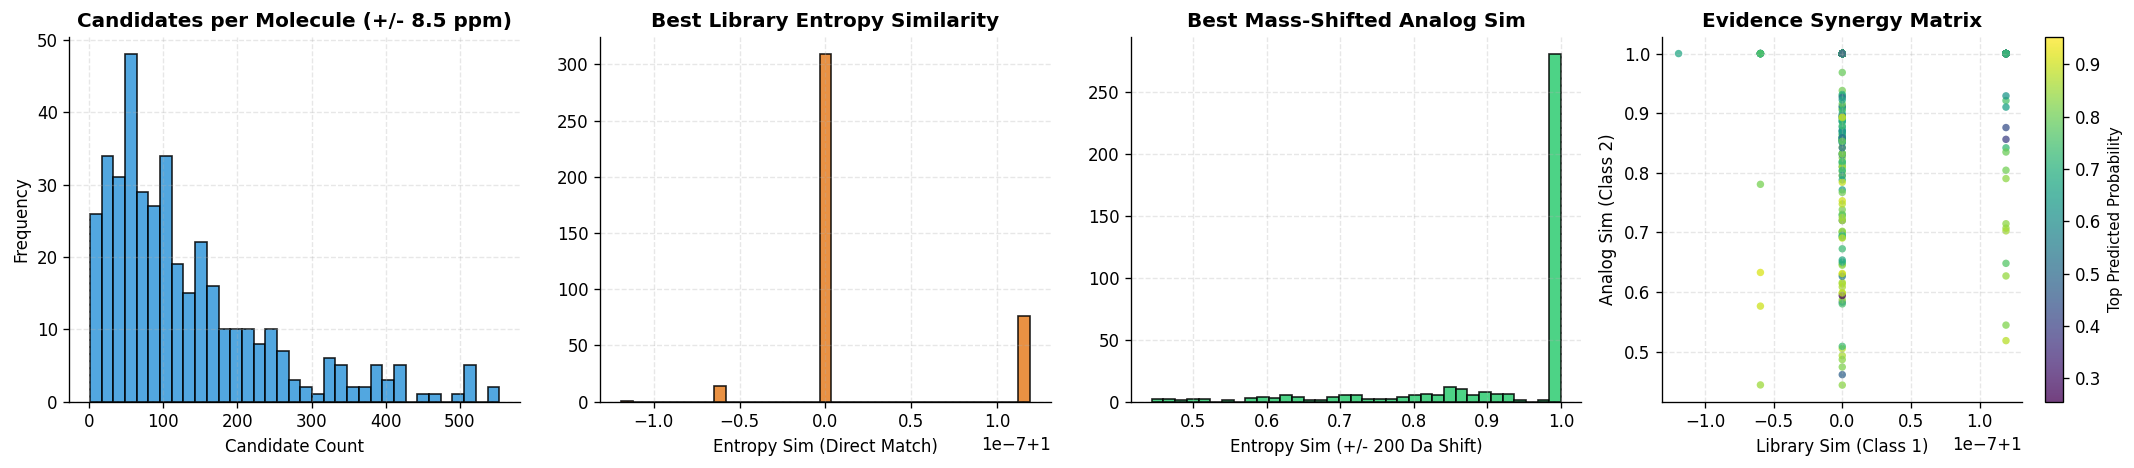


Molecules with confident library hit (>0.85): 100.0%
Molecules powered by Analog Propagation & Neural Model: 0.0%


In [11]:
# ===================================================================================
#  Diagnostic Dashboard: Evidence Alignment & Candidate Multiplicity
# ===================================================================================
d = pd.DataFrame(diag, columns=['molecule_id', 'neutral_mass', 'n_candidates',
                                'best_library_sim', 'best_analog_sim', 'top_prob'])

print("\n--- Test Cohort Empirical Summary ---")
print(d[['n_candidates', 'best_library_sim', 'best_analog_sim', 'top_prob']].describe().round(3).to_string())

fig, ax = plt.subplots(1, 4, figsize=(18, 4), dpi=120)

ax[0].hist(d.n_candidates, bins=35, color='#3498db', edgecolor='black', alpha=0.85)
ax[0].set_title('Candidates per Molecule (+/- 8.5 ppm)', fontweight='bold')
ax[0].set_xlabel('Candidate Count')
ax[0].set_ylabel('Frequency')

ax[1].hist(d.best_library_sim, bins=35, color='#e67e22', edgecolor='black', alpha=0.85)
ax[1].set_title('Best Library Entropy Similarity', fontweight='bold')
ax[1].set_xlabel('Entropy Sim (Direct Match)')

ax[2].hist(d.best_analog_sim, bins=35, color='#2ecc71', edgecolor='black', alpha=0.85)
ax[2].set_title('Best Mass-Shifted Analog Sim', fontweight='bold')
ax[2].set_xlabel('Entropy Sim (+/- 200 Da Shift)')

scatter = ax[3].scatter(d.best_library_sim, d.best_analog_sim, c=d.top_prob, cmap='viridis', s=20, alpha=0.75, edgecolors='none')
cbar = plt.colorbar(scatter, ax=ax[3])
cbar.set_label('Top Predicted Probability', fontsize=9)
ax[3].set_xlabel('Library Sim (Class 1)')
ax[3].set_ylabel('Analog Sim (Class 2)')
ax[3].set_title('Evidence Synergy Matrix', fontweight='bold')

for a in ax:
    a.spines[['top', 'right']].set_visible(False)
    a.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

likely_c1 = (d.best_library_sim > 0.85).mean()
print(f"\nMolecules with confident library hit (>0.85): {likely_c1:.1%}")
print(f"Molecules powered by Analog Propagation & Neural Model: {1 - likely_c1:.1%}")
